# Predicting Building Permit Processing Delays in Vancouver

## 1. Problem Statement and Objectives
Building permit delays affect housing supply, construction costs and project timelines.
This project uses issued building permits from the City of Vancouver Open Data Portal
(permits created 2017-2025) to predict whether a permit is processed **on time**
(at or below the median of 85 days) or **delayed**, using characteristics known at the time of application.

**Objectives**
1. Explore the data and identify what is associated with delays.
2. Build and compare different classification models(70/30 train/test split).
3. Identify the most influential factors.
4. Group permits with clustering (bonus).

In [1]:
# Importing Required Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
SEED = 42

In [2]:
# Project paths and loading the dataset
PROJECT_ROOT = Path("..")
DATA_FILE = PROJECT_ROOT / "data" / "clean" / "permits_clean.csv"
FIG_DIR = PROJECT_ROOT / "outputs" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA_FILE)
print(df.shape)
df.head()

(47438, 14)


,type_of_work,property_use,area,permit_category,log_value,project_value,value_is_zero,has_contractor,created_year,created_month,lat,lon,elapsed_days,on_time
0,Addition / Alteration,Service Uses,Downtown,Unknown,11.918397,150000.0,0,0,2023,2,49.281555,-123.120953,53,1
1,Addition / Alteration,Dwelling Uses,Riley Park,Renovation - Residential - Lower Complexity,12.429220,250000.0,0,0,2024,3,49.249743,-123.102202,29,1
2,Addition / Alteration,Dwelling Uses,Dunbar-Southlands,Unknown,10.308986,30000.0,0,0,2021,9,49.246779,-123.178988,579,0
3,Addition / Alteration,Retail Uses,Downtown,Renovation - Commercial/ Mixed Use - Lower Com...,12.429220,250000.0,0,0,2023,11,49.283397,-123.117746,31,1
4,Addition / Alteration,Office Uses,Downtown,Renovation - Commercial/ Mixed Use - Lower Com...,11.849405,140000.0,0,1,2024,1,49.287709,-123.118014,8,1


In [3]:
# Data overview
df.info()
print()
print(df.describe().round(2).T)
print()
cat_cols = df.select_dtypes(exclude="number").columns.tolist()
print("Categorical columns:", cat_cols)
print(df[cat_cols].nunique())

<class 'pandas.DataFrame'>
RangeIndex: 47438 entries, 0 to 47437
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   type_of_work     47438 non-null  str    
 1   property_use     47438 non-null  str    
 2   area             47438 non-null  str    
 3   permit_category  47438 non-null  str    
 4   log_value        47438 non-null  float64
 5   project_value    47438 non-null  float64
 6   value_is_zero    47438 non-null  int64  
 7   has_contractor   47438 non-null  int64  
 8   created_year     47438 non-null  int64  
 9   created_month    47438 non-null  int64  
 10  lat              47090 non-null  float64
 11  lon              47090 non-null  float64
 12  elapsed_days     47438 non-null  int64  
 13  on_time          47438 non-null  int64  
dtypes: float64(4), int64(6), str(4)
memory usage: 5.1 MB

                  count       mean          std      min       25%       50%  \
log_value       47438.0    

### Column descriptions
| Column | Meaning |
|---|---|
| type_of_work | Kind of work (new building, alteration, demolition, etc.) |
| property_use | Intended use of the property (top 20 uses; rest grouped as "Other") |
| area | Vancouver local area / neighbourhood |
| permit_category | Permit complexity category ("Unknown" if not given) |
| project_value, log_value | Declared project value, and its log transform |
| value_is_zero | 1 if the declared value is 0 |
| has_contractor | 1 if a building contractor is listed |
| created_year, created_month | When the application was created |
| lat, lon | Project coordinates (used for mapping and clustering) |
| elapsed_days | Days from application to issue (**used for EDA only, never as a feature**) |
| on_time | **Target**: 1 = at or below the 85-day median, 0 = delayed |

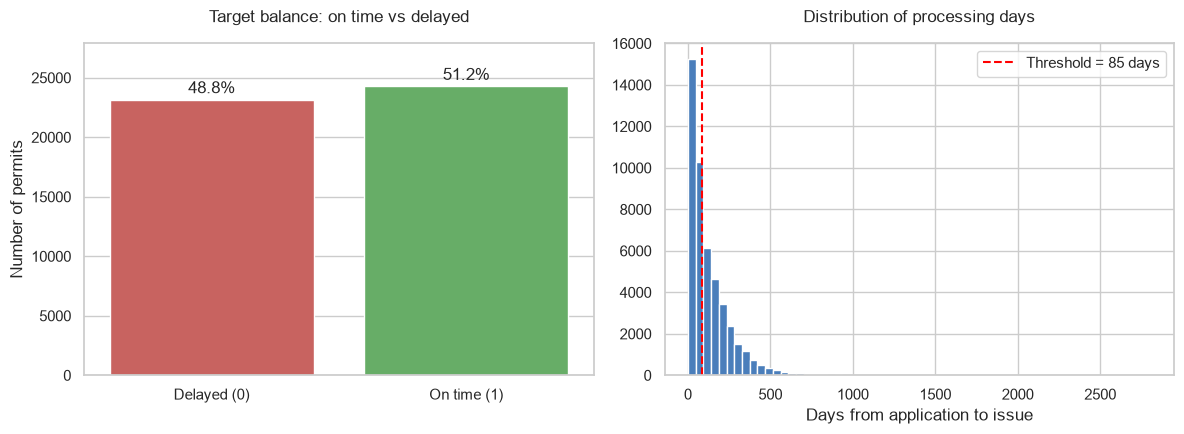

In [4]:
# Visualizing the target column
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

counts = df["on_time"].value_counts().sort_index()
labels = ["Delayed (0)", "On time (1)"]
sns.barplot(x=labels, y=counts.values, hue=labels, palette=["#d9534f", "#5cb85c"], legend=False, ax=ax[0])
for i, v in enumerate(counts.values):
    ax[0].text(i, v + counts.max() * 0.01, f"{v/len(df):.1%}", ha="center", va="bottom", fontsize=12)
ax[0].set_ylim(0, counts.max() * 1.15)
ax[0].set_title("Target balance: on time vs delayed", pad=15)
ax[0].set_ylabel("Number of permits")

ax[1].hist(df["elapsed_days"], bins=60, color="#4a7ebb")
ax[1].axvline(85, color="red", linestyle="--", label="Threshold = 85 days")
ax[1].set_title("Distribution of processing days", pad=15)
ax[1].set_xlabel("Days from application to issue")
ax[1].legend()

plt.tight_layout()
plt.savefig(FIG_DIR / "01_target_distribution.png", dpi=150)
plt.show()

<p><b>describe()</b> output shows that elapsed_days in the 2017-2025 data has a median of 83, not 85. The 85 comes from the full file, which we used to define the target before filtering the data.So,the threshold was fixed at the full-dataset median before the window filter, and it gives a 51/49 split.</p>

## 2. Exploratory Data Analysis
### 2.1 On-time rate by categorical features
Each bar shows the share of permits processed on time in that group. The dashed line is the overall
on-time rate (51.2%); green bars are above it, red bars below. `n` is the number of permits in the group.

In [5]:
# Plotting function

In [6]:
overall = df["on_time"].mean()

def rate_plot(col, ax, min_n=1, title=None):
    g = (df.groupby(col)["on_time"].agg(["mean", "size"])
           .query("size >= @min_n").sort_values("mean"))
    colors = ["#d9534f" if m < overall else "#5cb85c" for m in g["mean"]]
    ax.barh(g.index.astype(str), g["mean"], color=colors)
    ax.axvline(overall, color="black", linestyle="--", linewidth=1, label=f"Overall {overall:.1%}")
    for i, (m, n) in enumerate(zip(g["mean"], g["size"])):
        ax.text(m + 0.01, i, f"{m:.0%} (n={n:,})", va="center", fontsize=9)
    ax.set_xlim(0, 1.2)
    ax.set_xlabel("Share of permits processed on time")
    ax.set_title(title or f"On-time rate by {col}", pad=12)
    ax.legend(loc="lower right")

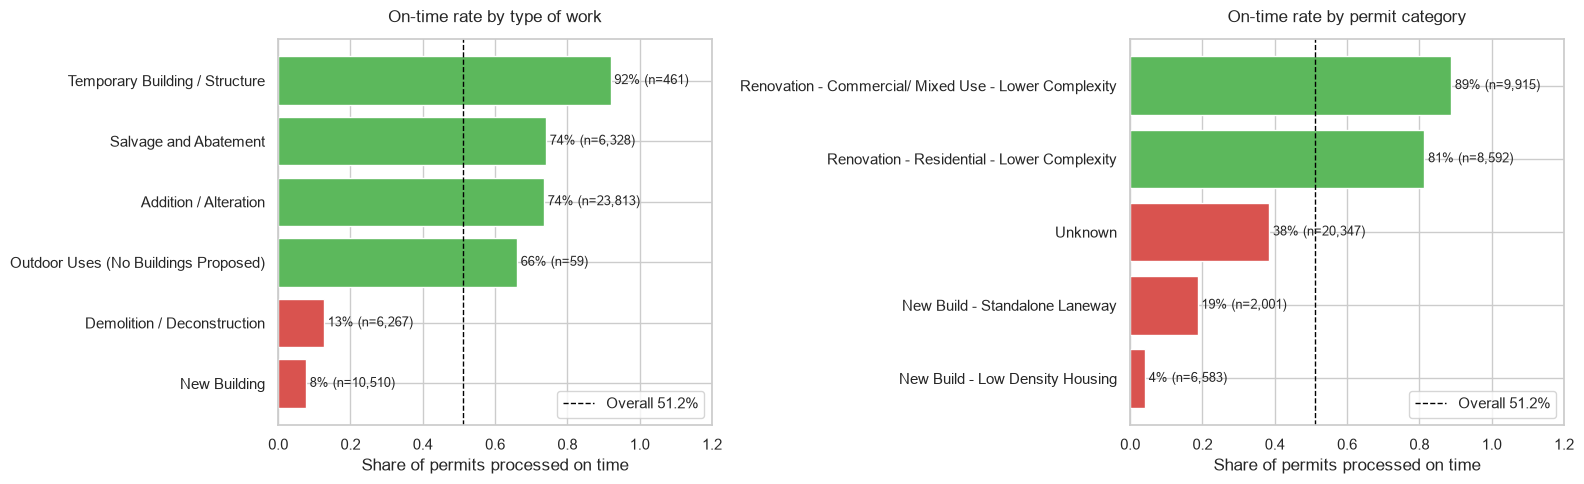

In [7]:
# Type of work and permit category
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
rate_plot("type_of_work", ax[0], title="On-time rate by type of work")
rate_plot("permit_category", ax[1], title="On-time rate by permit category")
plt.tight_layout()
plt.savefig(FIG_DIR / "02_ontime_by_work_and_category.png", dpi=150)
plt.show()

<p><b>Observations:- </b>1.Type of work: A huge spread, from about 8% on time for New Building and 13% for Demolition up to 92% for Temporary Building. Addition / Alteration and Salvage and Abatement are both about 74%.</p><p>2.Permit category: New Build - Low Density Housing is about 4% on time and Standalone Laneway about 19%. Both renovation categories are 81% to 89%, and “Unknown” is about 38%.</p>

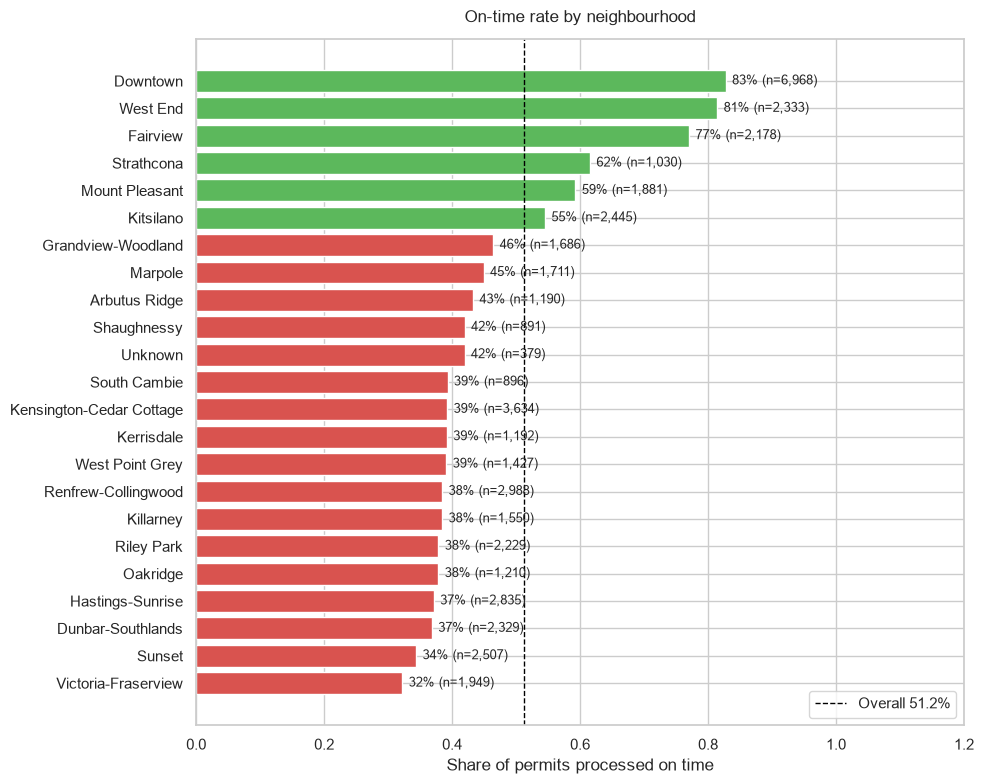

In [8]:
# Visualizing neighbourhood
fig, ax = plt.subplots(figsize=(10, 8))
rate_plot("area", ax, title="On-time rate by neighbourhood")
plt.tight_layout()
plt.savefig(FIG_DIR / "03_ontime_by_area.png", dpi=150)
plt.show()

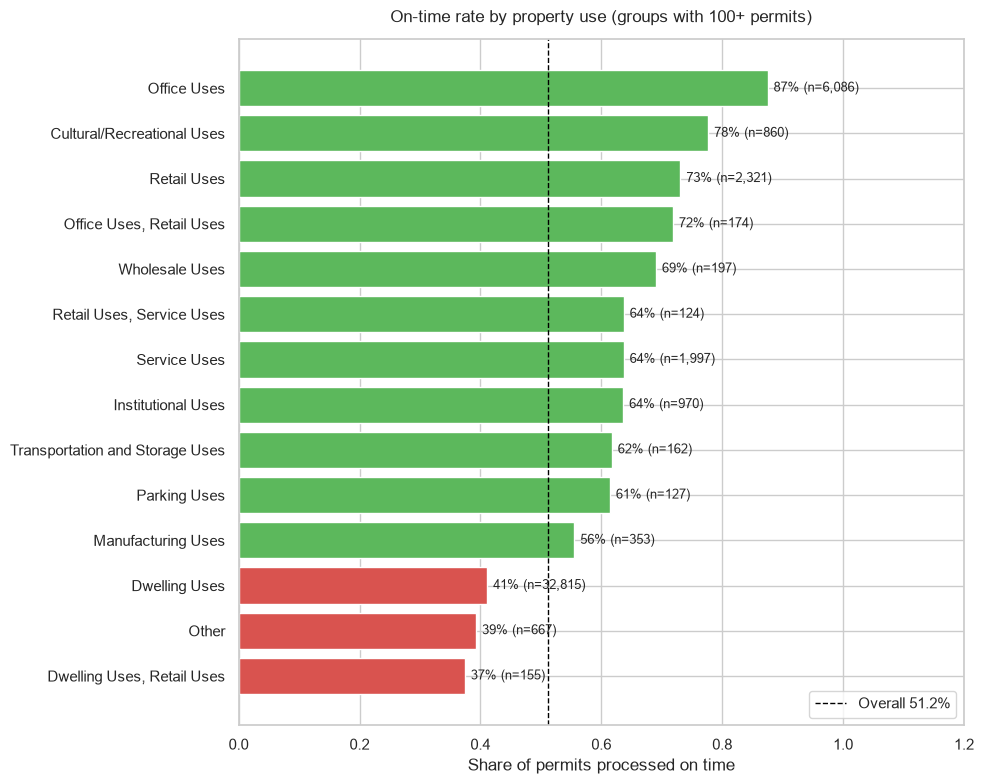

In [9]:
# Property Use
fig, ax = plt.subplots(figsize=(10, 8))
rate_plot("property_use", ax, min_n=100, title="On-time rate by property use (groups with 100+ permits)")
plt.tight_layout()
plt.savefig(FIG_DIR / "04_ontime_by_property_use.png", dpi=150)
plt.show()

### 2.2 Project value, contractor and timing
How the on-time rate changes with project size, whether a contractor is listed, and when the application was created.

In [10]:
# Project Value

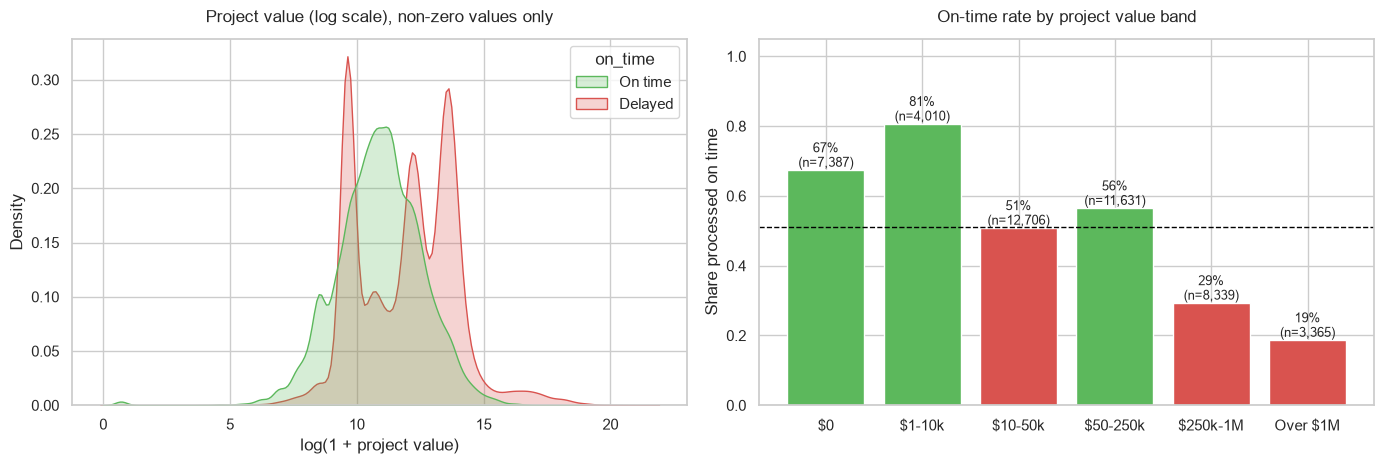

In [11]:
bins = [-0.1, 0, 10_000, 50_000, 250_000, 1_000_000, np.inf]
band_labels = ["$0", "$1-10k", "$10-50k", "$50-250k", "$250k-1M", "Over $1M"]
df["value_band"] = pd.cut(df["project_value"], bins=bins, labels=band_labels)   # EDA-only helper column

g = df.groupby("value_band", observed=True)["on_time"].agg(["mean", "size"])

fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))

nz = df[df["value_is_zero"] == 0]
sns.kdeplot(data=nz, x="log_value", hue=nz["on_time"].map({0: "Delayed", 1: "On time"}),
            fill=True, common_norm=False,
            palette={"Delayed": "#d9534f", "On time": "#5cb85c"}, ax=ax[0])
ax[0].set_title("Project value (log scale), non-zero values only", pad=12)
ax[0].set_xlabel("log(1 + project value)")

ax[1].bar(g.index.astype(str), g["mean"],
          color=["#d9534f" if m < overall else "#5cb85c" for m in g["mean"]])
ax[1].axhline(overall, color="black", linestyle="--", linewidth=1)
for i, (m, n) in enumerate(zip(g["mean"], g["size"])):
    ax[1].text(i, m + 0.01, f"{m:.0%}\n(n={n:,})", ha="center", fontsize=9)
ax[1].set_ylim(0, 1.05)
ax[1].set_title("On-time rate by project value band", pad=12)
ax[1].set_ylabel("Share processed on time")

plt.tight_layout()
plt.savefig(FIG_DIR / "05_value_vs_ontime.png", dpi=150)
plt.show()

<p><b>Observation:- </b>Very small and very large projects behave very differently, so the models should pick up value as a useful feature.</p>

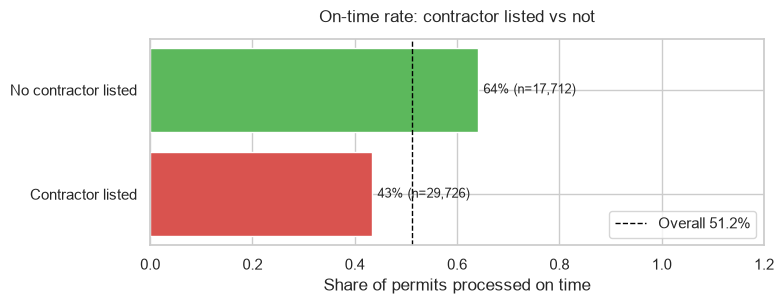

In [12]:
# Contractor Listed
df["contractor"] = df["has_contractor"].map({0: "No contractor listed", 1: "Contractor listed"})   # EDA-only

fig, ax = plt.subplots(figsize=(8, 3.2))
rate_plot("contractor", ax, title="On-time rate: contractor listed vs not")
plt.tight_layout()
plt.savefig(FIG_DIR / "06_contractor_vs_ontime.png", dpi=150)
plt.show()

<p><b>Observation:- </b>43% on time with a contractor listed and 64% without. Treat this as an association. Contractors are probably listed on bigger, more complex projects.</p>

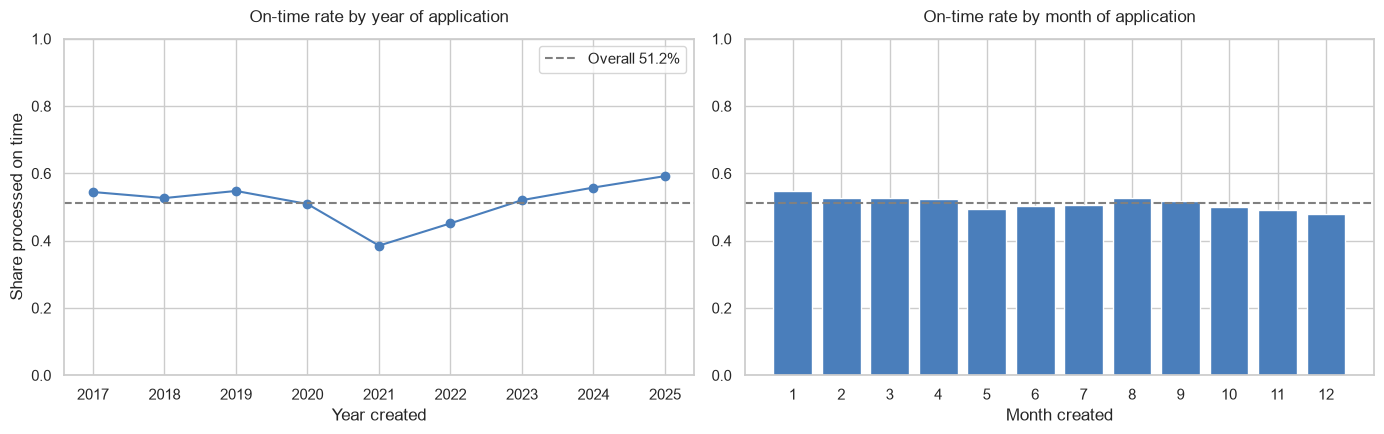

In [13]:
# Year and Month
by_year = df.groupby("created_year")["on_time"].agg(["mean", "size"])
by_month = df.groupby("created_month")["on_time"].agg(["mean", "size"])

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))

ax[0].plot(by_year.index, by_year["mean"], marker="o", color="#4a7ebb")
ax[0].axhline(overall, color="gray", linestyle="--", label=f"Overall {overall:.1%}")
ax[0].set_ylim(0, 1)
ax[0].set_title("On-time rate by year of application", pad=12)
ax[0].set_xlabel("Year created")
ax[0].set_ylabel("Share processed on time")
ax[0].legend()

ax[1].bar(by_month.index, by_month["mean"], color="#4a7ebb")
ax[1].axhline(overall, color="gray", linestyle="--")
ax[1].set_ylim(0, 1)
ax[1].set_xticks(range(1, 13))
ax[1].set_title("On-time rate by month of application", pad=12)
ax[1].set_xlabel("Month created")

plt.tight_layout()
plt.savefig(FIG_DIR / "07_year_month_trend.png", dpi=150)
plt.show()

<p><b>Observation:- </b>the yearly rate stays between roughly 52% and 59% in most years, with dips in 2021 (about 39%) and 2022 (about 45%). Month-to-month variation is small, from about 55% in January to about 48% in December. Timing looks like a weak signal</p>

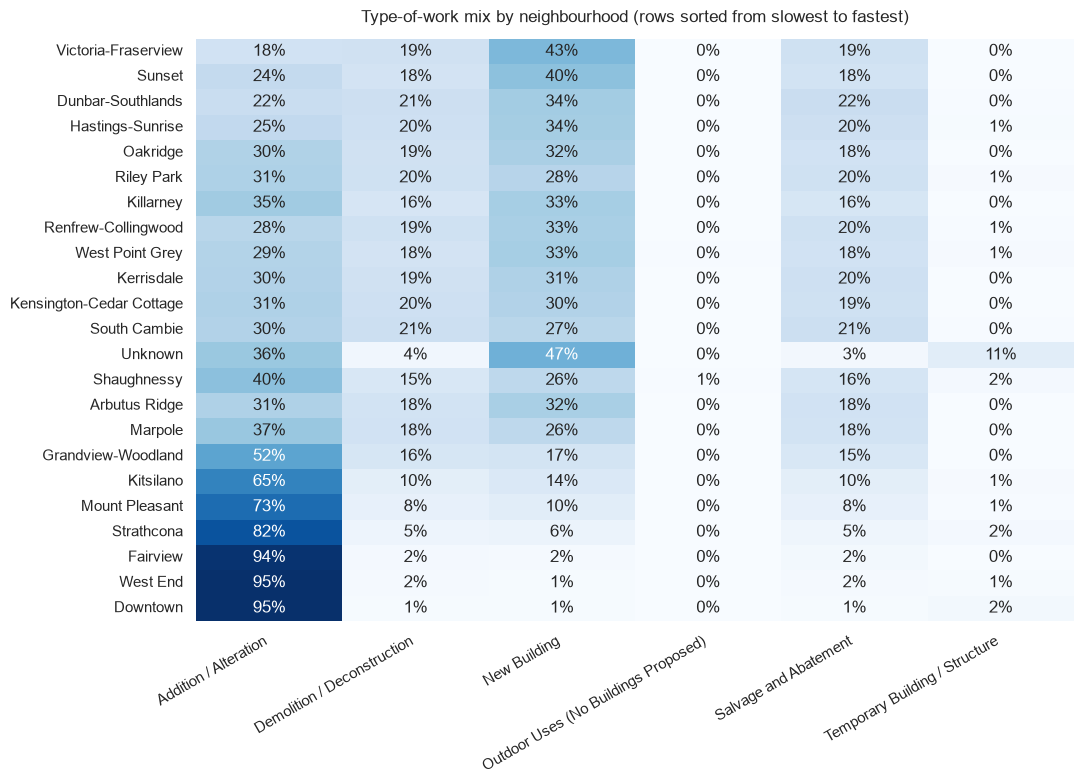

In [14]:
# Checking the confounding in type of work by neighbourhood
order = df.groupby("area")["on_time"].mean().sort_values().index
mix = pd.crosstab(df["area"], df["type_of_work"], normalize="index").loc[order]

fig, ax = plt.subplots(figsize=(11, 8))
sns.heatmap(mix, annot=True, fmt=".0%", cmap="Blues", cbar=False, ax=ax)
ax.set_title("Type-of-work mix by neighbourhood (rows sorted from slowest to fastest)", pad=12)
ax.set_xlabel("")
ax.set_ylabel("")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(FIG_DIR / "08_work_mix_by_area.png", dpi=150)
plt.show()

<p><b>Note:- </b>the neighbourhood and property-use differences are driven by what kind of work is done there, not by the place itself. Outer neighbourhoods likely have more new houses, which are slow, while Downtown has mostly commercial renovations, which are fast. About 95% of Downtown’s permits are alterations, while about 40% of Sunset’s are new buildings, which are slow.</p>

### 2.3 Correlations and geography
Correlations cover the numeric features only; categorical features were compared in section 2.1.
`elapsed_days` is shown for reference only: the target is defined from it, so its strong negative correlation is by construction.

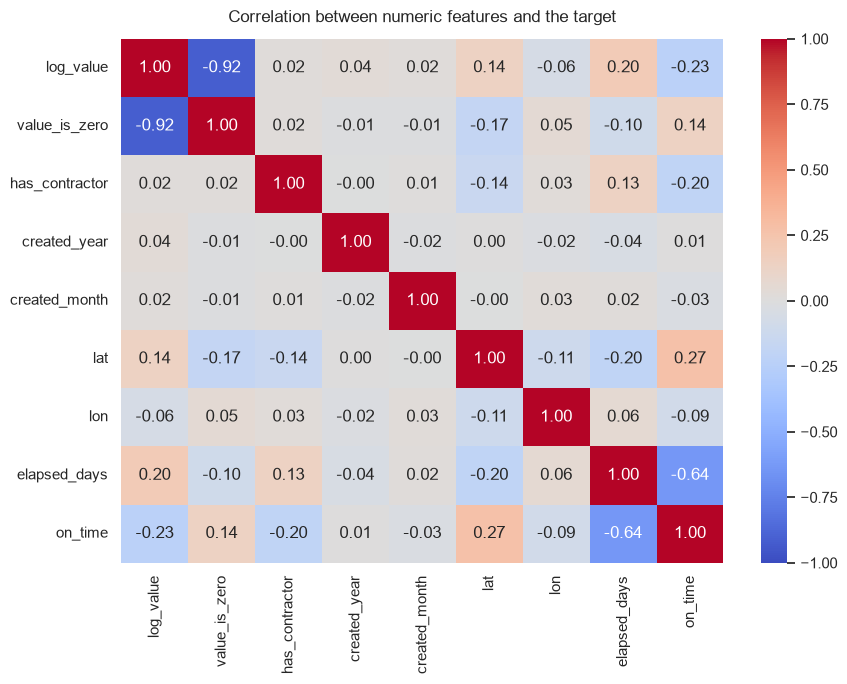

elapsed_days     -0.640133
log_value        -0.229729
has_contractor   -0.200412
lon              -0.090024
created_month    -0.027067
created_year      0.007074
value_is_zero     0.138710
lat               0.269803
Name: on_time, dtype: float64

In [15]:
# Correlation heatmap
num_cols = ["log_value", "value_is_zero", "has_contractor", "created_year",
            "created_month", "lat", "lon", "elapsed_days", "on_time"]
corr = df[num_cols].corr()

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlation between numeric features and the target", pad=12)
plt.tight_layout()
plt.savefig(FIG_DIR / "09_correlation_heatmap.png", dpi=150)
plt.show()

corr["on_time"].drop("on_time").sort_values()

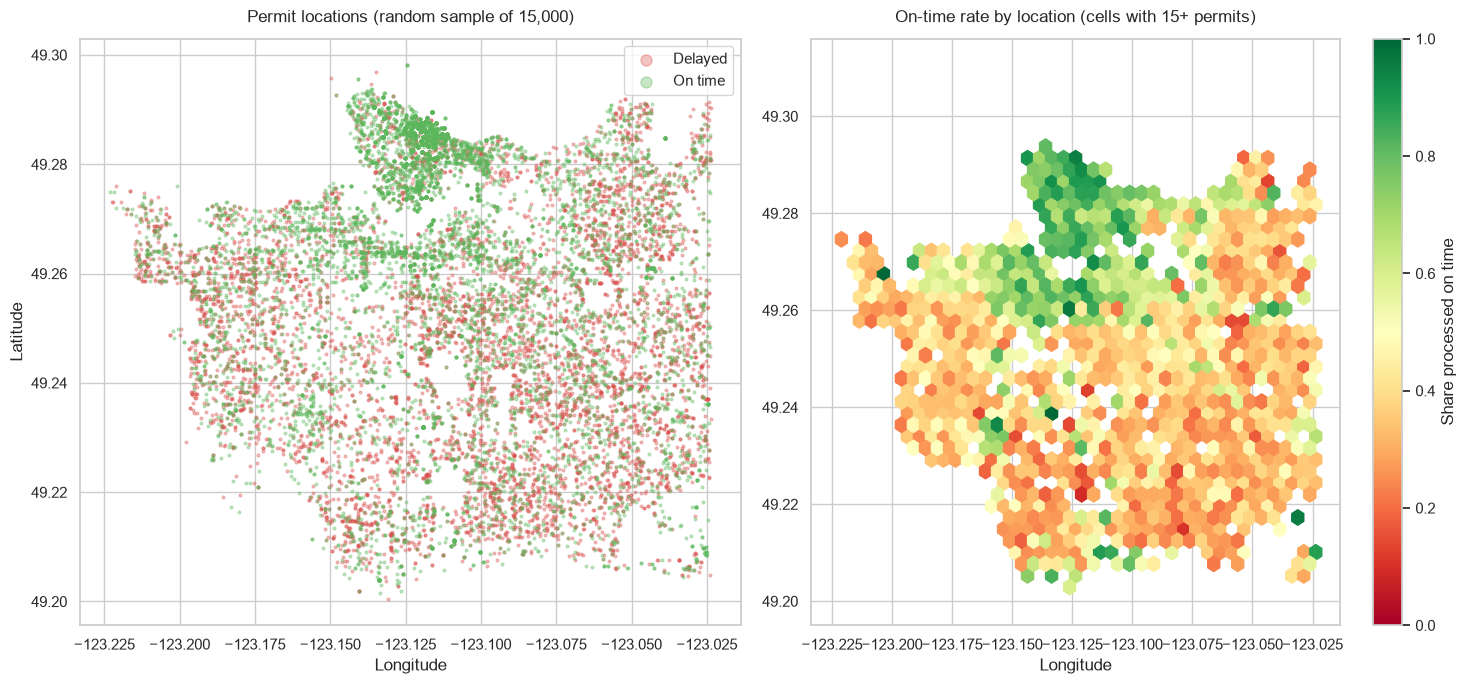

In [16]:
# Map of permits
geo = df.dropna(subset=["lat", "lon"])
sample = geo.sample(15000, random_state=SEED)

fig, ax = plt.subplots(1, 2, figsize=(15, 7))

for value, color, label in [(0, "#d9534f", "Delayed"), (1, "#5cb85c", "On time")]:
    d = sample[sample["on_time"] == value]
    ax[0].scatter(d["lon"], d["lat"], s=4, alpha=0.35, c=color, label=label)
ax[0].legend(markerscale=4)
ax[0].set_title("Permit locations (random sample of 15,000)", pad=12)
ax[0].set_xlabel("Longitude")
ax[0].set_ylabel("Latitude")

hb = ax[1].hexbin(geo["lon"], geo["lat"], C=geo["on_time"], reduce_C_function=np.mean,
                  gridsize=40, cmap="RdYlGn", mincnt=15, vmin=0, vmax=1)
plt.colorbar(hb, ax=ax[1], label="Share processed on time")
ax[1].set_title("On-time rate by location (cells with 15+ permits)", pad=12)
ax[1].set_xlabel("Longitude")

plt.tight_layout()
plt.savefig(FIG_DIR / "10_map_ontime.png", dpi=150)
plt.show()

## 3. Train/Test Split and Preprocessing
- **Split:** 70% train / 30% test, stratified on `on_time`, `random_state=42`, made once and shared by all models.
- **Features:** only information known at application time. `elapsed_days` (defines the target), coordinates and EDA-only helper columns are excluded.
- **Preprocessing:** one-hot encoding for categorical features and standardisation for numeric ones, fitted on the training data only (inside a pipeline), so nothing from the test set leaks in.

In [17]:
# The features list

In [18]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

USE_YEAR = True    # open decision A: later we re-run the models with False and compare

CAT_FEATURES = ["type_of_work", "property_use", "area", "permit_category"]
NUM_FEATURES = ["log_value", "value_is_zero", "has_contractor", "created_month"]
if USE_YEAR:
    NUM_FEATURES.append("created_year")

FEATURES = CAT_FEATURES + NUM_FEATURES
TARGET = "on_time"

assert "elapsed_days" not in FEATURES and TARGET not in FEATURES   # guard against leakage
print(len(FEATURES), "features:", FEATURES)

9 features: ['type_of_work', 'property_use', 'area', 'permit_category', 'log_value', 'value_is_zero', 'has_contractor', 'created_month', 'created_year']


In [19]:
## the 70/30 split
X = df[FEATURES]
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=SEED
)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("On-time share  train:", round(y_train.mean(), 4), "| test:", round(y_test.mean(), 4))

SPLIT_DIR = PROJECT_ROOT / "data" / "split"
SPLIT_DIR.mkdir(parents=True, exist_ok=True)
pd.concat([X_train, y_train], axis=1).to_csv(SPLIT_DIR / "train.csv", index=False)
pd.concat([X_test, y_test], axis=1).to_csv(SPLIT_DIR / "test.csv", index=False)

Train: (33206, 9) | Test: (14232, 9)
On-time share  train: 0.5118 | test: 0.5117


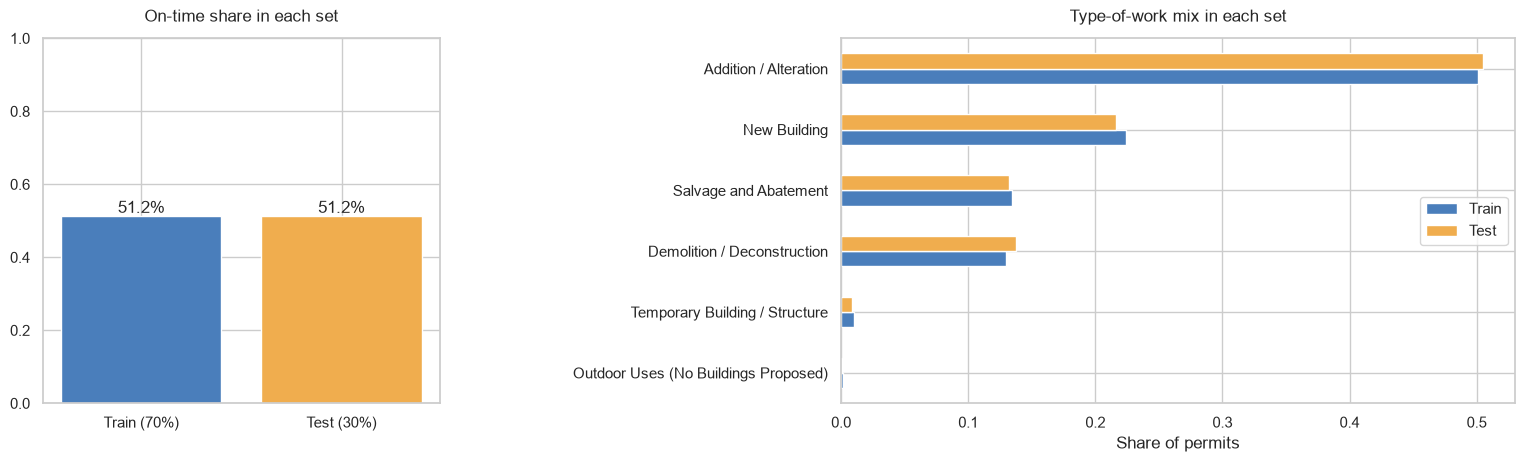

In [22]:
# check the split is representative
fig, ax = plt.subplots(1, 2, figsize=(16, 5),
                       gridspec_kw={"width_ratios": [1, 1.7], "wspace": 0.75})

shares = [y_train.mean(), y_test.mean()]
ax[0].bar(["Train (70%)", "Test (30%)"], shares, color=["#4a7ebb", "#f0ad4e"])
for i, s in enumerate(shares):
    ax[0].text(i, s + 0.01, f"{s:.1%}", ha="center")
ax[0].set_ylim(0, 1)
ax[0].set_title("On-time share in each set", pad=12)

work = pd.DataFrame({
    "Train": X_train["type_of_work"].value_counts(normalize=True),
    "Test": X_test["type_of_work"].value_counts(normalize=True),
}).sort_values("Train")
work.plot.barh(ax=ax[1], color=["#4a7ebb", "#f0ad4e"])
ax[1].set_title("Type-of-work mix in each set", pad=12)
ax[1].set_xlabel("Share of permits")
ax[1].set_ylabel("")
ax[1].legend(loc="center right")

fig.subplots_adjust(left=0.06, right=0.98, bottom=0.15, top=0.88)
plt.savefig(FIG_DIR / "11_split_check.png", dpi=150)
plt.show()